# Análisis exploratorio

Solo se usa **train**: val y test no se miran hasta la evaluación final, para que ninguna decisión dependa de ellos.

Requiere `make data` y `make prepare`.

In [1]:
import pandas as pd

from oil_rnn.config import get, load_config
from oil_rnn.data import load_split

cfg = load_config()
train = load_split("train")
train.shape

(4551, 22)

In [2]:
train.head()

,date,brent,wti,henry_hub,ecb_deposit_rate,usd_per_eur,cny_per_usd,vix,brent_fut_open,brent_fut_high,...,brent_fut_volume,wti_fut_open,wti_fut_high,wti_fut_low,wti_fut_close,wti_fut_volume,copper,gold,dollar_index,_context
0,2000-01-04,23.95,25.56,NaN,2.0,1.0309,8.2799,27.01,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.410004,False
1,2000-01-05,23.72,24.65,NaN,2.0,1.0335,8.2798,26.41,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.379997,False
2,2000-01-06,23.55,24.79,NaN,2.0,1.0324,8.2797,25.73,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.650002,False
3,2000-01-07,23.35,24.79,NaN,2.0,1.0294,8.2794,21.72,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.800003,False
4,2000-01-10,22.77,24.71,2.2,2.0,1.0252,8.2794,21.71,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.989998,False


In [3]:
train.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,4551,NaN,NaN,NaN,2009-12-31 02:59:24.403427,2000-01-04 00:00:00,2005-07-04 12:00:00,2010-02-23 00:00:00,2014-09-03 12:00:00,2019-02-22 00:00:00,NaN
brent,4551.0,NaN,NaN,NaN,66.437499,16.51,42.905,61.73,91.43,143.95,30.278547
wti,4551.0,NaN,NaN,NaN,63.603184,17.5,43.14,60.66,86.075,145.31,26.42998
henry_hub,4547.0,NaN,NaN,NaN,4.644726,1.49,3.0,4.01,5.715,18.48,2.255756
ecb_deposit_rate,4551.0,NaN,NaN,NaN,0.928906,-0.4,-0.1,0.25,2.0,3.75,1.270416
usd_per_eur,4551.0,NaN,NaN,NaN,1.223471,0.827,1.1211,1.2422,1.34015,1.601,0.164299
cny_per_usd,4551.0,NaN,NaN,NaN,7.147173,6.0402,6.38815,6.8326,8.2765,8.28,0.818255
vix,4551.0,NaN,NaN,NaN,19.507748,9.14,13.43,17.3,22.89,80.86,8.638669
brent_fut_open,2922.0,NaN,NaN,NaN,81.228871,27.950001,56.7775,77.73,107.697498,146.080002,26.220258
brent_fut_high,2922.0,NaN,NaN,NaN,82.079103,28.969999,57.545001,78.529999,108.457499,147.429993,26.282344


## Valores vacíos por columna

In [4]:
train.isna().sum().loc[lambda s: s > 0]

henry_hub              4
brent_fut_open      1629
brent_fut_high      1629
brent_fut_low       1629
brent_fut_close     1629
brent_fut_volume    1629
wti_fut_open         133
wti_fut_high         133
wti_fut_low          133
wti_fut_close        133
wti_fut_volume       133
copper               137
gold                 137
dtype: int64

## Variable objetivo

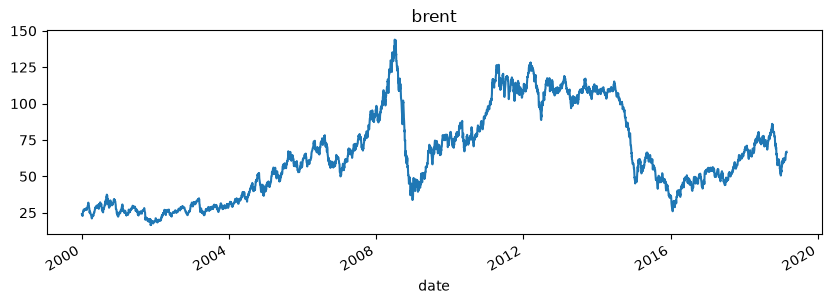

In [5]:
target = get(cfg, "data.target")
time_col = get(cfg, "data.time_column")
if target == "PENDIENTE":
    print("data.target sigue PENDIENTE en configs/config.yaml")
elif time_col not in (None, "PENDIENTE"):
    train.plot(x=time_col, y=target, figsize=(10, 3), legend=False, title=target)
elif pd.api.types.is_numeric_dtype(train[target]):
    train[target].plot.hist(bins=30, title=target)
else:
    train[target].value_counts().plot.bar(title=target)

## Primera fecha con dato de cada columna

Los vacíos del inicio no se pueden rellenar con valores pasados. Una columna que empieza tarde obliga a quitarla de `data.features` o a recortar el comienzo de la serie.

In [6]:
import numpy as np

t = train.set_index(time_col)
numeric = t.select_dtypes("number")
pd.DataFrame(
    {
        "primera_fecha": numeric.apply(lambda s: s.first_valid_index()),
        "vacios": numeric.isna().sum(),
        "pct_vacios": (numeric.isna().mean() * 100).round(1),
    }
).sort_values("primera_fecha")

,primera_fecha,vacios,pct_vacios
brent,2000-01-04,0,0.0
vix,2000-01-04,0,0.0
cny_per_usd,2000-01-04,0,0.0
usd_per_eur,2000-01-04,0,0.0
dollar_index,2000-01-04,0,0.0
wti,2000-01-04,0,0.0
ecb_deposit_rate,2000-01-04,0,0.0
henry_hub,2000-01-10,4,0.1
wti_fut_open,2000-08-23,133,2.9
wti_fut_high,2000-08-23,133,2.9


## Valores no positivos

El rendimiento logarítmico exige precios positivos. El WTI cotizó en negativo el 20/04/2020; aquí se comprueba si ese día cae en train y si alguna otra columna tiene valores ≤ 0.

In [7]:
non_positive = (numeric <= 0).sum()
has_any = (non_positive > 0).any()
print(non_positive[non_positive > 0] if has_any else "Ninguna columna con valores <= 0")
print("Fin de train:", t.index.max().date())

ecb_deposit_rate    1682
brent_fut_volume       6
wti_fut_volume         5
dtype: int64
Fin de train: 2019-02-22


## Nivel frente a rendimiento

Una serie estacionaria mantiene media y varianza a lo largo del tiempo. Se compara el precio con su rendimiento logarítmico diario: autocorrelación a 1 día y media por tramos de cuatro años.

In [8]:
price = t[target]
ret1 = np.log(price).diff().dropna()
print(f"Autocorrelación a 1 día · nivel: {price.autocorr(1):.3f}")
print(f"Autocorrelación a 1 día · rendimiento: {ret1.autocorr(1):.3f}")
by_period = pd.DataFrame(
    {
        "precio_medio": price.groupby(price.index.year // 4 * 4).mean(),
        "rendimiento_medio_diario": ret1.groupby(ret1.index.year // 4 * 4).mean(),
        "volatilidad_diaria": ret1.groupby(ret1.index.year // 4 * 4).std(),
    }
).round(4)
by_period

Autocorrelación a 1 día · nivel: 0.999
Autocorrelación a 1 día · rendimiento: 0.014


,precio_medio,rendimiento_medio_diario,volatilidad_diaria
date,,,
2000,26.9324,0.0003,0.0293
2004,58.1641,0.0012,0.0208
2008,87.3037,0.0001,0.0259
2012,92.6953,-0.0011,0.0168
2016,56.5383,0.0008,0.0219


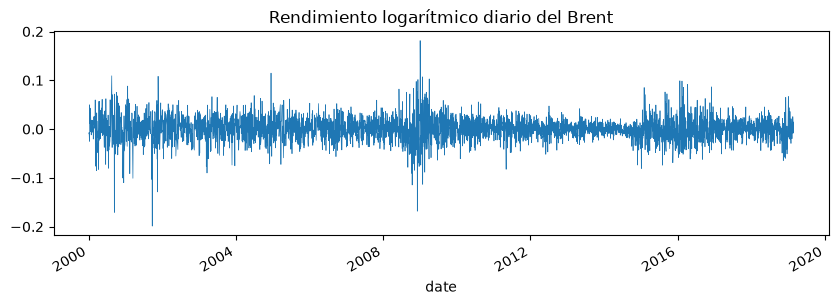

In [9]:
title = "Rendimiento logarítmico diario del Brent"
ax = ret1.plot(figsize=(10, 3), linewidth=0.5, title=title)

## Rendimiento a cada horizonte

Para cada horizonte h: dispersión del rendimiento a h días y sus cuantiles 10, 50 y 90. Esos cuantiles son la referencia trivial del intervalo del 80 %. La autocorrelación se calcula con rendimientos no solapados (uno cada h días): si es cercana a cero, el rendimiento pasado no anticipa el siguiente y la persistencia es difícil de superar.

In [10]:
rows = []
for h in (5, 21, 63, 252):
    r = np.log(price).diff(h).dropna()
    independent = r.iloc[::h]
    rows.append(
        {
            "horizonte": h,
            "desv_tipica": r.std(),
            "q10": r.quantile(0.1),
            "q50": r.quantile(0.5),
            "q90": r.quantile(0.9),
            "n_no_solapados": len(independent),
            "autocorr_no_solapada": independent.autocorr(1),
        }
    )
pd.DataFrame(rows).set_index("horizonte").round(3)

,desv_tipica,q10,q50,q90,n_no_solapados,autocorr_no_solapada
horizonte,,,,,,
5,0.053,-0.065,0.004,0.063,910,0.011
21,0.110,-0.137,0.015,0.131,216,-0.076
63,0.196,-0.233,0.032,0.222,72,0.000
252,0.356,-0.544,0.078,0.472,18,-0.104


## Volatilidad por régimen

Desviación típica móvil de 21 días del rendimiento diario, anualizada. Los tramos de volatilidad alta son los que más pesan en el error.

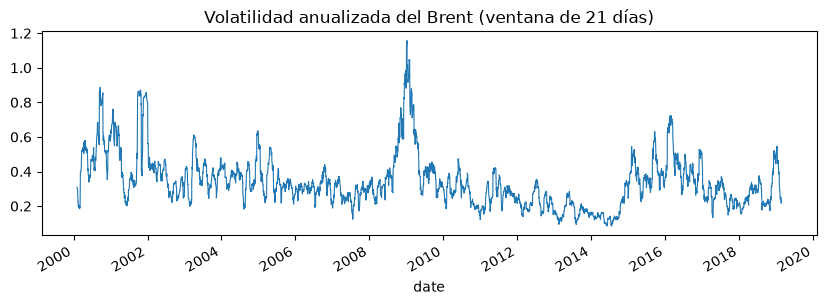

In [11]:
vol = ret1.rolling(21).std() * np.sqrt(252)
title = "Volatilidad anualizada del Brent (ventana de 21 días)"
ax = vol.plot(figsize=(10, 3), linewidth=0.8, title=title)

## Relación de cada variable con el rendimiento futuro del Brent

Correlación entre el rendimiento de cada variable en los últimos 21 días y el rendimiento del Brent en los h días siguientes. Las ventanas se solapan, así que estos valores orientan la elección de `data.features` pero no son un contraste estadístico. El tipo del BCE y los volúmenes se usan en diferencias, no en logaritmos.

In [12]:
prices = [c for c in numeric.columns if not c.endswith("_volume")]
positive = [c for c in prices if (numeric[c].dropna() > 0).all()]
past = np.log(numeric[positive]).diff(21)
table = {}
for h in (5, 21, 63, 252):
    future = np.log(price).shift(-h) - np.log(price)
    table[h] = past.corrwith(future)
pd.DataFrame(table).round(3).sort_values(5, key=abs, ascending=False)

,5,21,63,252
brent_fut_close,0.098,0.209,0.166,-0.038
copper,0.092,0.178,0.247,0.086
brent_fut_high,0.087,0.209,0.164,-0.043
brent_fut_low,0.085,0.204,0.160,-0.039
vix,-0.080,-0.137,-0.127,-0.042
brent_fut_open,0.077,0.202,0.157,-0.043
cny_per_usd,-0.062,-0.068,-0.024,0.106
dollar_index,-0.054,-0.083,-0.141,-0.104
usd_per_eur,0.053,0.063,0.133,0.091
wti_fut_close,0.039,0.057,0.045,-0.040
